JS04 Praktikum 1 - K-Means pada dataset Iris.

In [1]:
# Shim: notebook tidak punya __file__, kode ini warisan script .py.
import os
__file__ = os.path.abspath("kmeans_iris.ipynb")
print("base:", os.path.dirname(__file__))

base: C:\code\pemmes26\js04-klasterisasi\praktikum-1


In [2]:
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.cluster import KMeans

DATA = Path(__file__).resolve().parents[1] / "data"
OUT = Path(__file__).resolve().parent / "output"
OUT.mkdir(exist_ok=True)

In [3]:
# 1. Persiapan data
df = pd.read_csv(DATA / "Iris.csv")
print(df.head(), "\n")

   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa 



In [4]:
# 2. Seleksi fitur: 4 fitur numerik, label Species disimpan terpisah
X = df.iloc[:, 1:-1]
y = df.iloc[:, -1]
print(X.head(), "\n")

   SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
0            5.1           3.5            1.4           0.2
1            4.9           3.0            1.4           0.2
2            4.7           3.2            1.3           0.2
3            4.6           3.1            1.5           0.2
4            5.0           3.6            1.4           0.2 



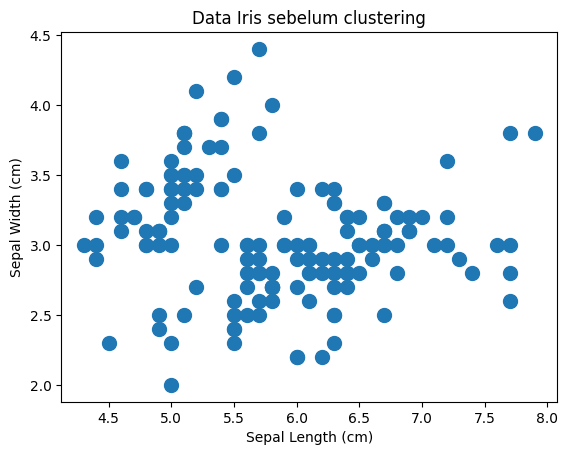

In [5]:
# 3. Plot data mentah (2 dimensi: Sepal Length vs Sepal Width)
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s=100)
plt.xlabel("Sepal Length (cm)")
plt.ylabel("Sepal Width (cm)")
plt.title("Data Iris sebelum clustering")
plt.savefig(OUT / "01_data_mentah.png", dpi=120, bbox_inches="tight")

Nilai SSE (k=2): 152.36870647733906


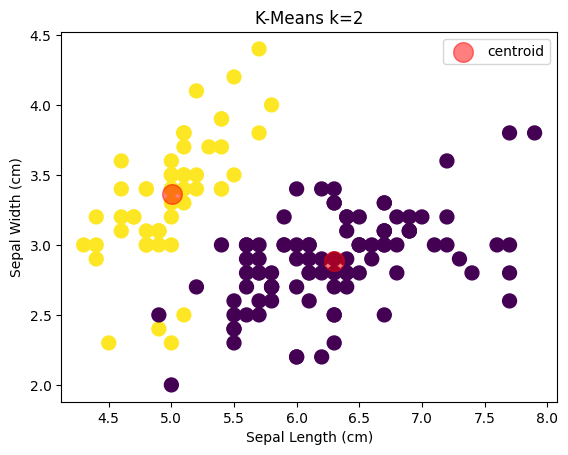

In [6]:
# 4. Model K-Means dengan k=2 (pura-pura tidak tahu labelnya ada 3)
cl_kmeans = KMeans(n_clusters=2, random_state=42)
y_kmeans = cl_kmeans.fit_predict(X)

plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s=100, c=y_kmeans)
centers = cl_kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c="red", s=200, alpha=0.5, label="centroid")
plt.xlabel("Sepal Length (cm)")
plt.ylabel("Sepal Width (cm)")
plt.title("K-Means k=2")
plt.legend()
plt.savefig(OUT / "02_kmeans_k2.png", dpi=120, bbox_inches="tight")

print(f"Nilai SSE (k=2): {cl_kmeans.inertia_}")

k=1; SSE=680.8244
k=2; SSE=152.36870647733906
k=3; SSE=78.9450658259773
k=4; SSE=57.440280212954754
k=5; SSE=46.535582051282056
k=6; SSE=39.251830892636775
k=7; SSE=35.042759952465836
k=8; SSE=30.217021122152705
k=9; SSE=28.756456196581205


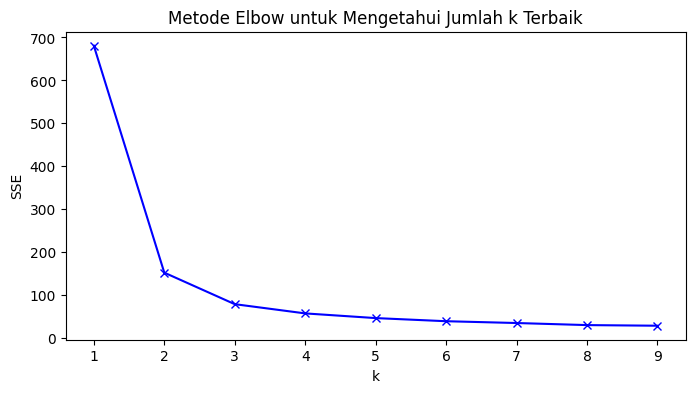

In [7]:
# 5. Metode elbow: cari k terbaik dari 1-9
K = range(1, 10)
sse = [KMeans(n_clusters=k, random_state=42).fit(X).inertia_ for k in K]

plt.figure(figsize=(8, 4))
plt.plot(K, sse, "bx-")
plt.xlabel("k")
plt.ylabel("SSE")
plt.title("Metode Elbow untuk Mengetahui Jumlah k Terbaik")
plt.savefig(OUT / "03_elbow.png", dpi=120, bbox_inches="tight")

for k, sse_val in zip(K, sse):
    print(f"k={k}; SSE={sse_val}")

In [8]:
# 6. k=3 sesuai titik siku, bandingkan dengan label asli
cl3 = KMeans(n_clusters=3, random_state=42)
y3 = cl3.fit_predict(X)
print(f"\nNilai SSE (k=3): {cl3.inertia_}")
print(pd.crosstab(y, y3, rownames=["Species asli"], colnames=["cluster"]))


Nilai SSE (k=3): 78.9450658259773
cluster           0   1   2
Species asli               
Iris-setosa       0  50   0
Iris-versicolor   3   0  47
Iris-virginica   36   0  14
